# 00 · Data and geometry: from sky images to the light-echo frame

**What this notebook does.**  It takes the seven JWST NIRCam F444W images of
the thermal light echo *Mab* and puts them on a common grid in the light-echo
frame (U, V, W).  Everything downstream works on this grid.

**Why.**  A light echo shows the dust that the supernova's light reaches at
the moment of observation.  That dust lies on a paraboloid with Cas A at its
focus.  At Mab the paraboloid is locally a thin sheet, so each image is a
*slice* through the interstellar medium.  Between epochs the paraboloid moves
outward, and successive images slice successively deeper layers.  Stacking
the slices gives the medium's 3D structure on scales of ~0.003-0.5 ly.

**The frame.**
- **W** is the normal to the paraboloid at Mab: the depth direction.
- **U, V** span the echo surface: the in-plane directions.

Each mosaic pixel images dust at a known 3D position (x, y, z), tabulated for
two reference dates in the input cubes `pos3d_60mas_<year>.npy`.  Projecting
onto U, V, W and interpolating the flux onto a regular (U, V) grid gives one
image per epoch at depth W_k.

Inputs: `data/inputs/` (see `data/MANIFEST.md`).  Outputs: `data/products/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from astropy.io import fits

from mabsf import config as C, data as D, geometry as G, plotting
from mabsf.checks import check, targets

plotting.style()
RECOMPUTE = False      # True: redo the resampling even if data/products/ already has it (~4 min)
D.check_inputs();

11 / 11 inputs present under data/inputs


## 1. The seven epochs

The visits span 345 days.  `MJD` is the mid-exposure date.  `dt` is the time
from the reference date of the first position cube, in years; positions at
each epoch are interpolated linearly between the two cubes.

In [2]:
pd.DataFrame([dict(epoch=k + 1, visit=v, MJD=round(m, 3), dt_yr=round(float(G.epoch_dt(m)), 4),
                   roll_deg=C.ROLLS_DEG[k]) for k, (v, m) in enumerate(C.EPOCHS)])

,epoch,visit,MJD,dt_yr,roll_deg
0,1,05451001001,60541.321,0.6338,197.8
1,2,05451002001,60569.073,0.7098,173.0
2,3,05451012001,60583.256,0.7486,163.0
3,4,05451003001,60599.205,0.7923,139.9
4,5,05451004001,60674.751,0.9993,60.8
5,6,08527029001,60870.255,1.5349,229.9
6,7,05451005001,60886.426,1.5792,217.4


## 2. One epoch on the sky

Each mosaic has stars and galaxies removed and replaced by an infill
(extension `INFILL_DRAW_1`).  Below is epoch 1 at 1/8 resolution, next to
the U and W coordinates of every pixel.

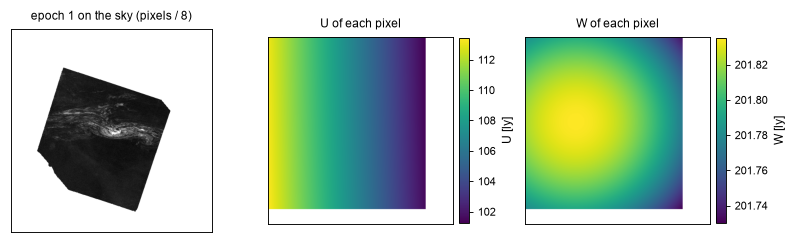

In [3]:
with fits.open(D.mosaic_path(C.EPOCHS[0][0])) as h:
    img = np.asarray(h['INFILL_DRAW_1'].data[::8, ::8], float)
pos = G.load_positions()
X, Y, Z = G.xyz_at(pos, G.epoch_dt(C.EPOCHS[0][1]))
U, V, W = G.project(X, Y, Z)

fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.6))
axs[0].imshow(img, origin='lower', cmap='gray', vmin=0.3, vmax=1.1)
axs[0].set_title('epoch 1 on the sky (pixels / 8)')
for a, q, lab in ((axs[1], U, 'U [ly]'), (axs[2], W, 'W [ly]')):
    im = a.imshow(q[::8, ::8], origin='lower', cmap='viridis')
    fig.colorbar(im, ax=a, fraction=0.046, pad=0.03, label=lab)
    a.set_title('%s of each pixel' % lab.split()[0])
for a in axs:
    a.set_xticks([]); a.set_yticks([])
fig.tight_layout()

U and W change smoothly across the mosaic, so locally the mapping from sky to
echo frame is close to linear.  It is sheared and rotated, though, so the PSF
is not round in (U, V); notebook 02 handles this with the local Jacobian
(`geometry.pixel_to_uv_jacobian`).

## 3. Resample every epoch onto one (U, V) grid

The grid step is 0.0032 ly, the size of one 60 mas pixel at Mab.  The grid
covers the first epoch's footprint.  For each epoch, the flux is
interpolated linearly from the pixel positions (U, V) onto the grid
(`scipy.interpolate.griddata`, Delaunay triangulation).  The epoch's depth
W_k is the mean W of its pixels, and its sky level is the median of the
resampled flux.

In [4]:
if RECOMPUTE or not os.path.exists(D.uv_cube_path('draw1')):
    G.resample_epochs('draw1')
cube = D.uv_cube('draw1')
Ug, Vg = D.uv_grids()
w, bg = D.epoch_w(), D.backgrounds()
print('UV cube', cube.shape, '| U %.2f-%.2f ly, V %.2f-%.2f ly' % (Ug[0, 0], Ug[0, -1], Vg[0, 0], Vg[-1, 0]))
pd.DataFrame(dict(epoch=np.arange(1, 8), W_ly=w.round(4), dW_from_epoch1=(w - w[0]).round(4), sky=bg.round(4)))

UV cube (7, 4043, 3800) | U 101.26-113.43 ly, V 49.86-62.79 ly


,epoch,W_ly,dW_from_epoch1,sky
0,1,201.8177,0.0000,0.3853
1,2,201.8652,0.0475,0.3797
2,3,201.8887,0.0710,0.3804
3,4,201.9123,0.0946,0.3816
4,5,202.0333,0.2156,0.3830
5,6,202.3392,0.5215,0.3885
6,7,202.3649,0.5472,0.3846


The seven slices span **0.55 ly in depth**, unevenly:
- **epochs 1-4**: 0.024-0.047 ly apart;
- **epoch 5**: 0.12 ly beyond epoch 4;
- **epochs 6-7**: a further 0.3 ly, and 0.026 ly from each other.

Close pairs probe depth structure on the same scales as the in-plane
structure; the long baselines probe larger depth scales.

## 4. The cloud in the echo frame

The colour composite shows epochs 2, 3 and 4 in red, green and blue, and is
the same image as panel A of the paper figure.  Structure that is identical
in all three slices is grey or white; structure that shifts or changes between
them appears in colour.

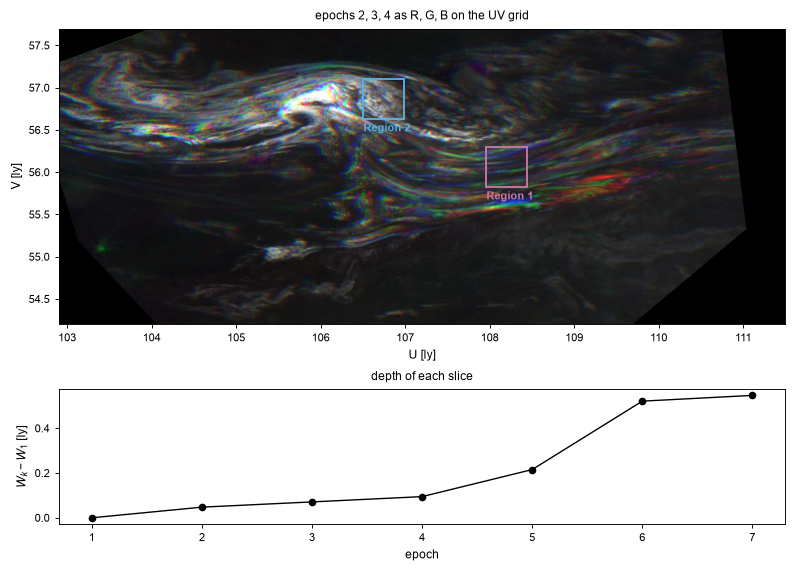

In [5]:
ulim, vlim = (102.9, 111.5), (54.2, 57.7)
r0, r1 = np.searchsorted(Vg[:, 0], vlim); c0, c1 = np.searchsorted(Ug[0], ulim)
sub = np.asarray(cube[:, r0:r1, c0:c1])
fig, axs = plt.subplots(2, 1, figsize=(plotting.W_IN, 5.2), gridspec_kw=dict(height_ratios=[2.4, 1]))
axs[0].imshow(plotting.rgb_composite(sub), origin='lower',
              extent=[Ug[0, c0], Ug[0, c1 - 1], Vg[r0, 0], Vg[r1 - 1, 0]])
for k, (r, c) in C.REGION_CENTERS.items():
    h = C.REGION_BOX // 2
    col = (plotting.C_R1, plotting.C_R2)[k - 1]
    axs[0].add_patch(Rectangle((Ug[0, c - h], Vg[r - h, 0]), C.REGION_BOX * C.PIX_LY, C.REGION_BOX * C.PIX_LY,
                               fc='none', ec=col, lw=1.2))
    axs[0].text(Ug[0, c - h], Vg[r - h, 0] - 0.05, 'Region %d' % k, color=col, va='top', fontweight='bold')
axs[0].set_xlabel('U [ly]'); axs[0].set_ylabel('V [ly]')
axs[0].set_title('epochs 2, 3, 4 as R, G, B on the UV grid')
axs[1].plot(np.arange(1, 8), w - w[0], 'ko-', ms=4)
axs[1].set_xlabel('epoch'); axs[1].set_ylabel(r'$W_k - W_1$ [ly]')
axs[1].set_title('depth of each slice')
fig.tight_layout()

Two regions are used as examples throughout:
- **Region 1** shows filaments that change colour between epochs: they move
  or change in depth.
- **Region 2** is a compact clump that drifts steadily and keeps its shape.

Notebook 04 quantifies both.

## 5. Check against the published analysis

The resampling is deterministic, so the grid, depths and sky levels must match
the original analysis exactly.

In [6]:
T = targets()['grid']
check('UV cube shape', cube.shape, T['shape'], rtol=0)
check('U, V grid origin [ly]', [Ug[0, 0], Vg[0, 0]], [T['U00'], T['V00']], rtol=1e-12)
check('epoch depths W_k [ly]', w, T['epoch_mean_w'], rtol=1e-12)
check('epoch sky levels', bg, T['backgrounds'], rtol=1e-12)
check('mean flux per epoch', [np.nanmean(cube[k]) for k in range(7)], T['epoch_nanmean'], rtol=1e-6)
check('finite pixels per epoch', [np.isfinite(cube[k]).sum() for k in range(7)], T['epoch_nfinite'], rtol=0)

ok   UV cube shape                                    [   7. 4043. 3800.]  (expected [   7. 4043. 3800.])
ok   U, V grid origin [ly]                            [101.25773  49.86423]  (expected [101.25773  49.86423])
ok   epoch depths W_k [ly]                            [201.81771 201.86523 201.88869 201.91235 202.03328 202.33925 202.36495]  (expected [201.81771 201.86523 201.88869 201.91235 202.03328 202.33925 202.36495])
ok   epoch sky levels                                 [0.38534 0.3797  0.3804  0.38158 0.38296 0.38852 0.38463]  (expected [0.38534 0.3797  0.3804  0.38158 0.38296 0.38852 0.38463])
ok   mean flux per epoch                              [0.40428 0.40355 0.40401 0.40446 0.40615 0.42504 0.42368]  (expected [0.40428 0.40355 0.40401 0.40446 0.40615 0.42504 0.42368])
ok   finite pixels per epoch                          [5388433. 4717991. 4854634. 5438358. 5465963. 5496404. 5326514.]  (expected [5388433. 4717991. 4854634. 5438358. 5465963. 5496404. 5326514.])
